In [1]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgbooster
from models.lstm import run_lstm
from utils.plots import plot_forecast

In [2]:
pretro_csv = 'data/petro.csv'

if not os.path.exists(pretro_csv):
    petr4_dataset = load_stock(STOCKS["petro"], "petro", force=True)
    petr4_dataset.head(10)

petr4_dataset = pd.read_csv(pretro_csv)

In [3]:
print(petr4_dataset.isna().sum())

date            0
petro_close     0
petro_high      0
petro_low       0
petro_open      0
petro_volume    0
ibovespa        0
vix             0
selic_daily     0
selic_goal      0
ipca            0
fx_usd          0
gdp             0
unemployment    0
dtype: int64


In [4]:
petr4_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2737 entries, 0 to 2736
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          2737 non-null   str    
 1   petro_close   2737 non-null   float64
 2   petro_high    2737 non-null   float64
 3   petro_low     2737 non-null   float64
 4   petro_open    2737 non-null   float64
 5   petro_volume  2737 non-null   int64  
 6   ibovespa      2737 non-null   float64
 7   vix           2737 non-null   float64
 8   selic_daily   2737 non-null   float64
 9   selic_goal    2737 non-null   float64
 10  ipca          2737 non-null   float64
 11  fx_usd        2737 non-null   float64
 12  gdp           2737 non-null   float64
 13  unemployment  2737 non-null   float64
dtypes: float64(12), int64(1), str(1)
memory usage: 299.5 KB


## ARIMA

In [5]:
train_petro, test_petro = split_temporal(petr4_dataset)
res_petro = run_arima(train_petro, test_petro, "petro")

--- Identificando ordem do ARIMA para PETRO ---
Performing stepwise search to minimize aic
 ARIMA(2,2,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.23 sec
 ARIMA(0,2,0)(0,0,0)[0] intercept   : AIC=960.897, Time=0.09 sec
 ARIMA(1,2,0)(0,0,0)[0] intercept   : AIC=319.391, Time=0.06 sec
 ARIMA(0,2,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.48 sec
 ARIMA(0,2,0)(0,0,0)[0]             : AIC=958.898, Time=0.03 sec
 ARIMA(2,2,0)(0,0,0)[0] intercept   : AIC=-26.297, Time=0.13 sec
 ARIMA(3,2,0)(0,0,0)[0] intercept   : AIC=-182.352, Time=0.18 sec
 ARIMA(4,2,0)(0,0,0)[0] intercept   : AIC=-286.417, Time=0.22 sec
 ARIMA(5,2,0)(0,0,0)[0] intercept   : AIC=-311.609, Time=0.26 sec
 ARIMA(5,2,1)(0,0,0)[0] intercept   : AIC=-570.266, Time=1.64 sec
 ARIMA(4,2,1)(0,0,0)[0] intercept   : AIC=-588.479, Time=1.28 sec
 ARIMA(3,2,1)(0,0,0)[0] intercept   : AIC=inf, Time=1.28 sec
 ARIMA(4,2,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.69 sec
 ARIMA(3,2,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.75 sec
 ARIMA(5,2,2)(

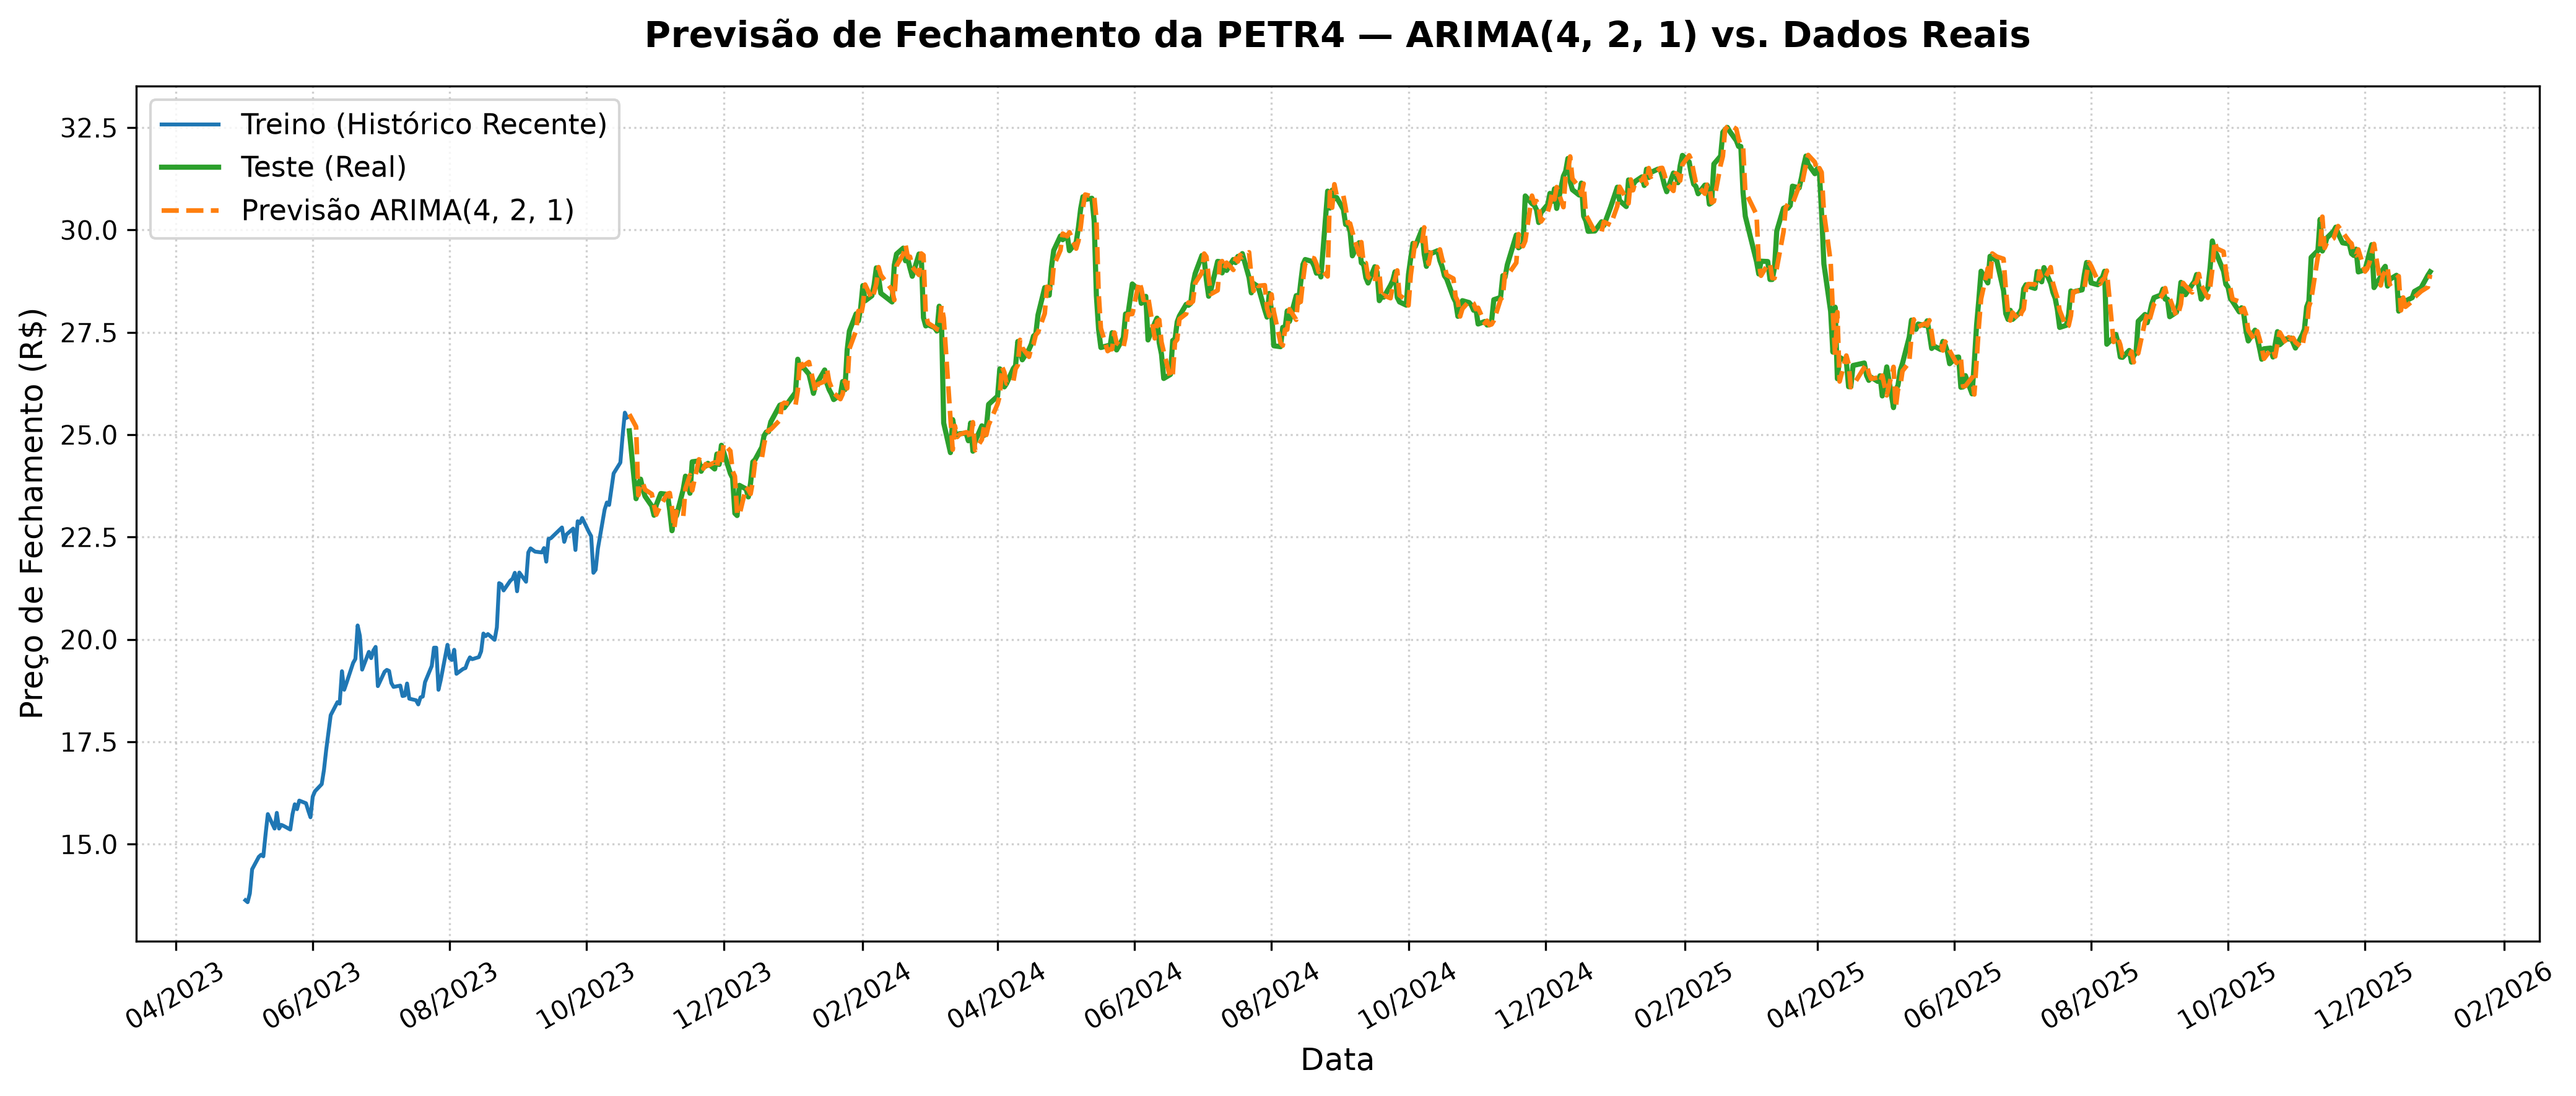

In [6]:
plot_forecast(
    train_petro, test_petro,
    predictions=res_petro["predictions"],
    stock_name="petro",
    model_name=f"ARIMA{res_petro['order']}",
    ticker_label="PETR4",
)

## XGBooster

--- XGBoost PETRO: 37 features, 2186 treino / 548 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
Melhor RMSE médio (validação): 1.8420
XGBoost petro          RMSE: 4.9691 | MAE: 4.5596 | MAPE: 15.75% | Acurácia direcional: 48.18%
Naive petro            RMSE: 0.4268 | MAE: 0.3031 | MAPE: 1.08% | Acurácia direcional: n/a
p-valor (teste binomial, acurácia direcional): 0.4170


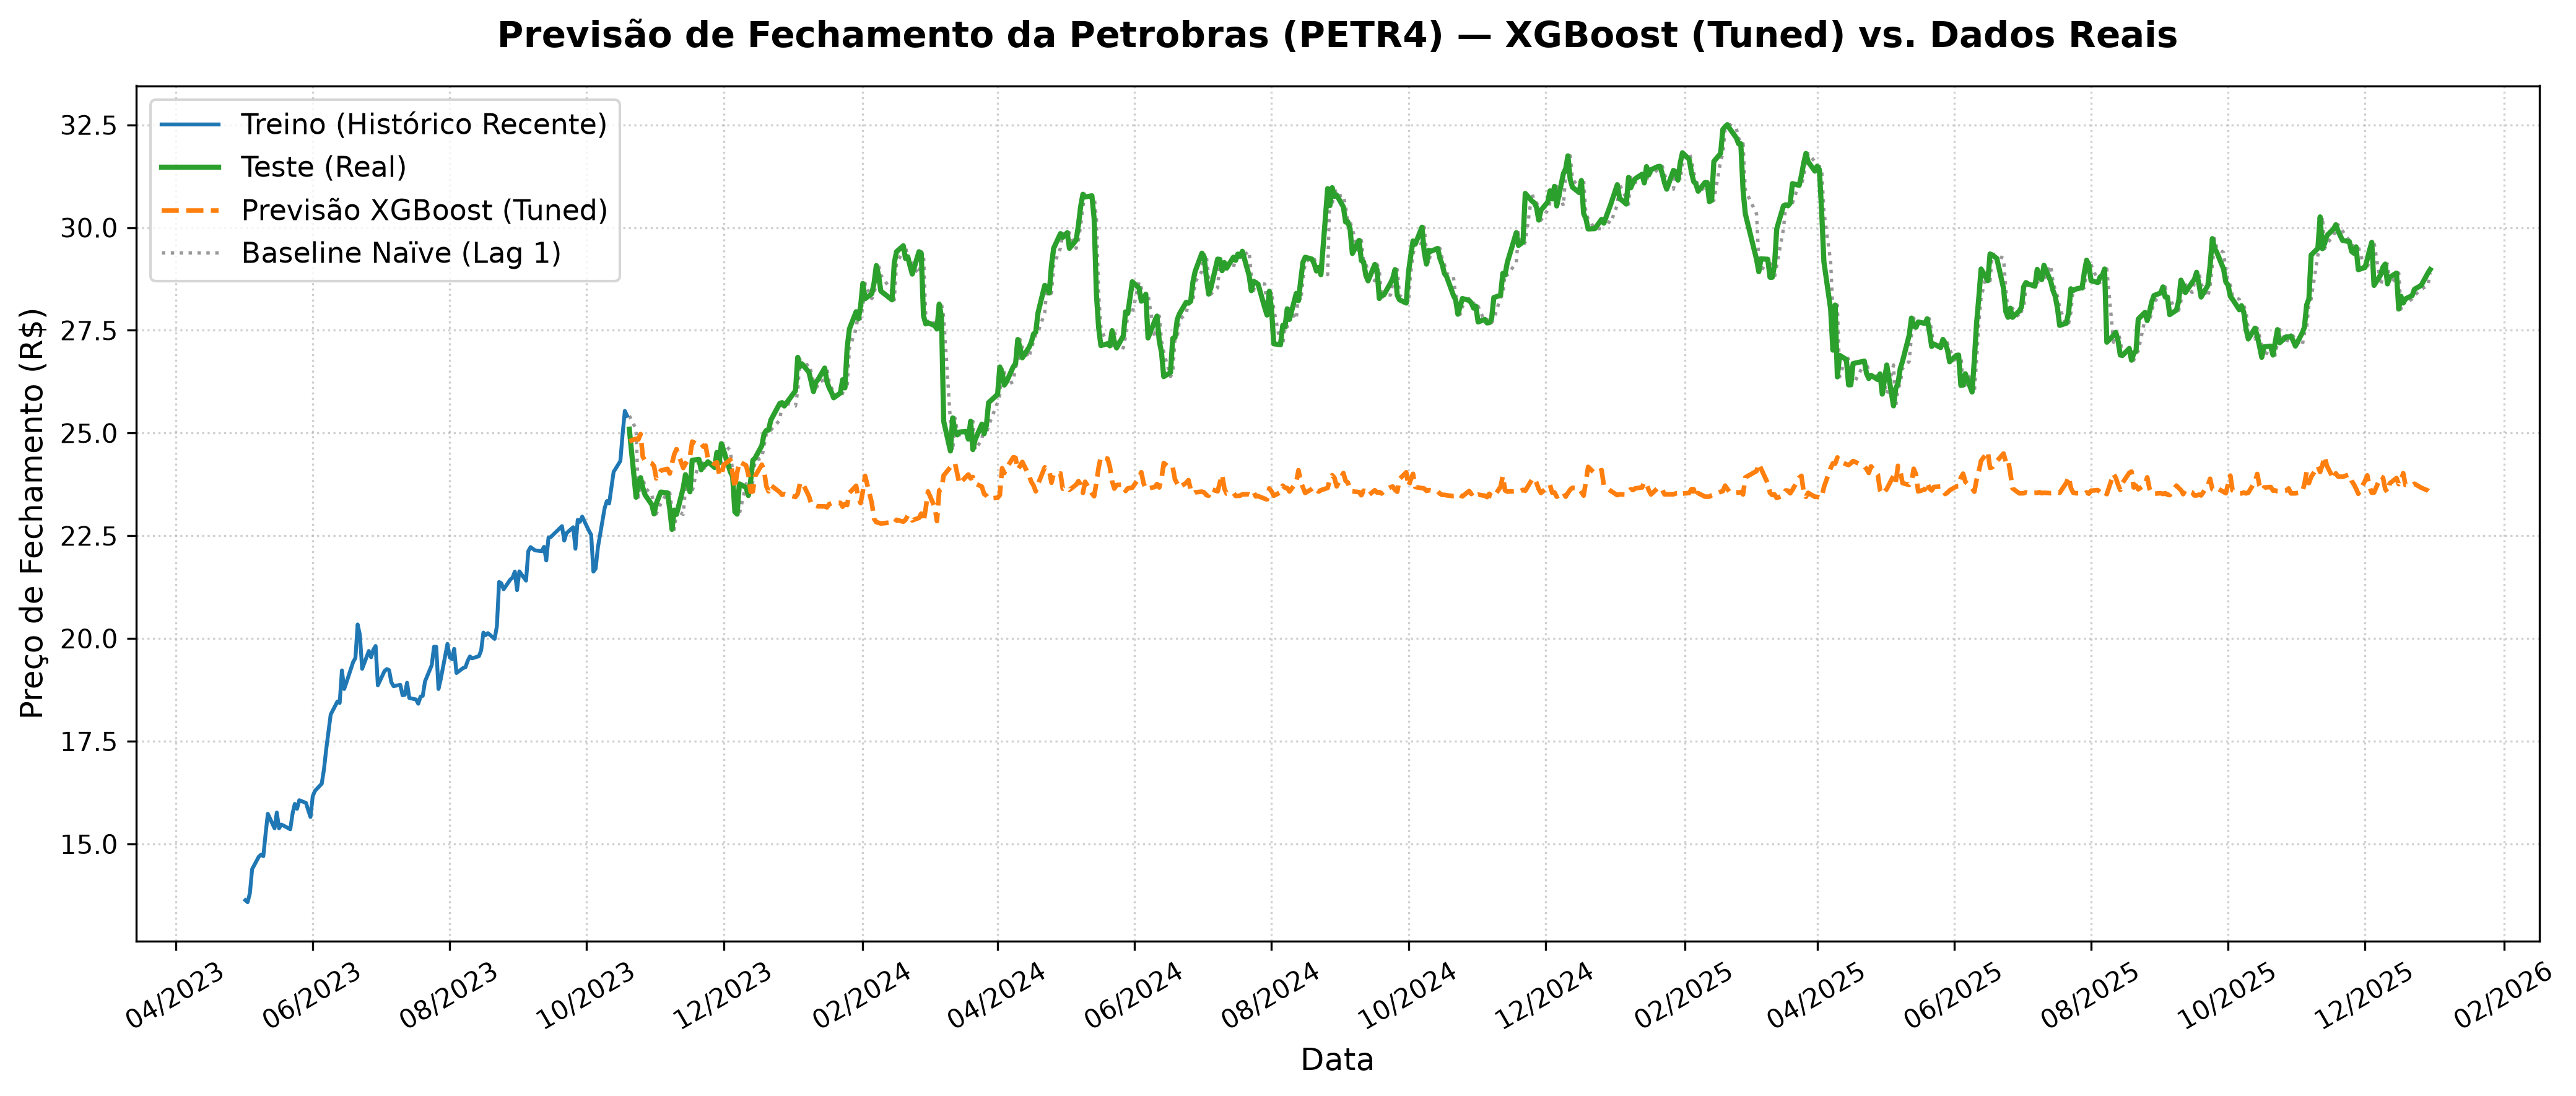

In [ ]:
res_xgbooster = run_xgbooster(train_petro, test_petro, "petro")
plot_forecast(
    train_petro, test_petro,
    predictions=res_xgbooster["predictions"],
    stock_name="petro",
    model_name="XGBoost (Tuned)",
    ticker_label="PETR4",
    company_name="Petrobras",
    baseline=res_xgbooster["ontem"],        # baseline naive (preço de ontem)
)

Trial 30 Complete [00h 00m 03s]
val_loss: 0.012324882671236992

Best val_loss So Far: 0.007518792990595102
Total elapsed time: 00h 00m 50s
Melhores hiperparâmetros: {'n_layers': 1, 'units_0': 128, 'dropout_0': 0.4, 'learning_rate': 0.001, 'units_1': 128, 'dropout_1': 0.2, 'units_2': 32, 'dropout_2': 0.0, 'tuner/epochs': 10, 'tuner/initial_epoch': 4, 'tuner/bracket': 2, 'tuner/round': 2, 'tuner/trial_id': '0012'}
Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0288 - mae: 0.1245 - val_loss: 0.0701 - val_mae: 0.2293
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0073 - mae: 0.0663 - val_loss: 0.0260 - val_mae: 0.1230
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - mae: 0.0525 - val_loss: 0.0181 - val_mae: 0.0996
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0041 - mae: 0.0496 - val_loss: 0.0229 - val_mae: 0.1160
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0038 - mae: 0.0472 - val_loss: 0.0247 - val_mae: 0.1222

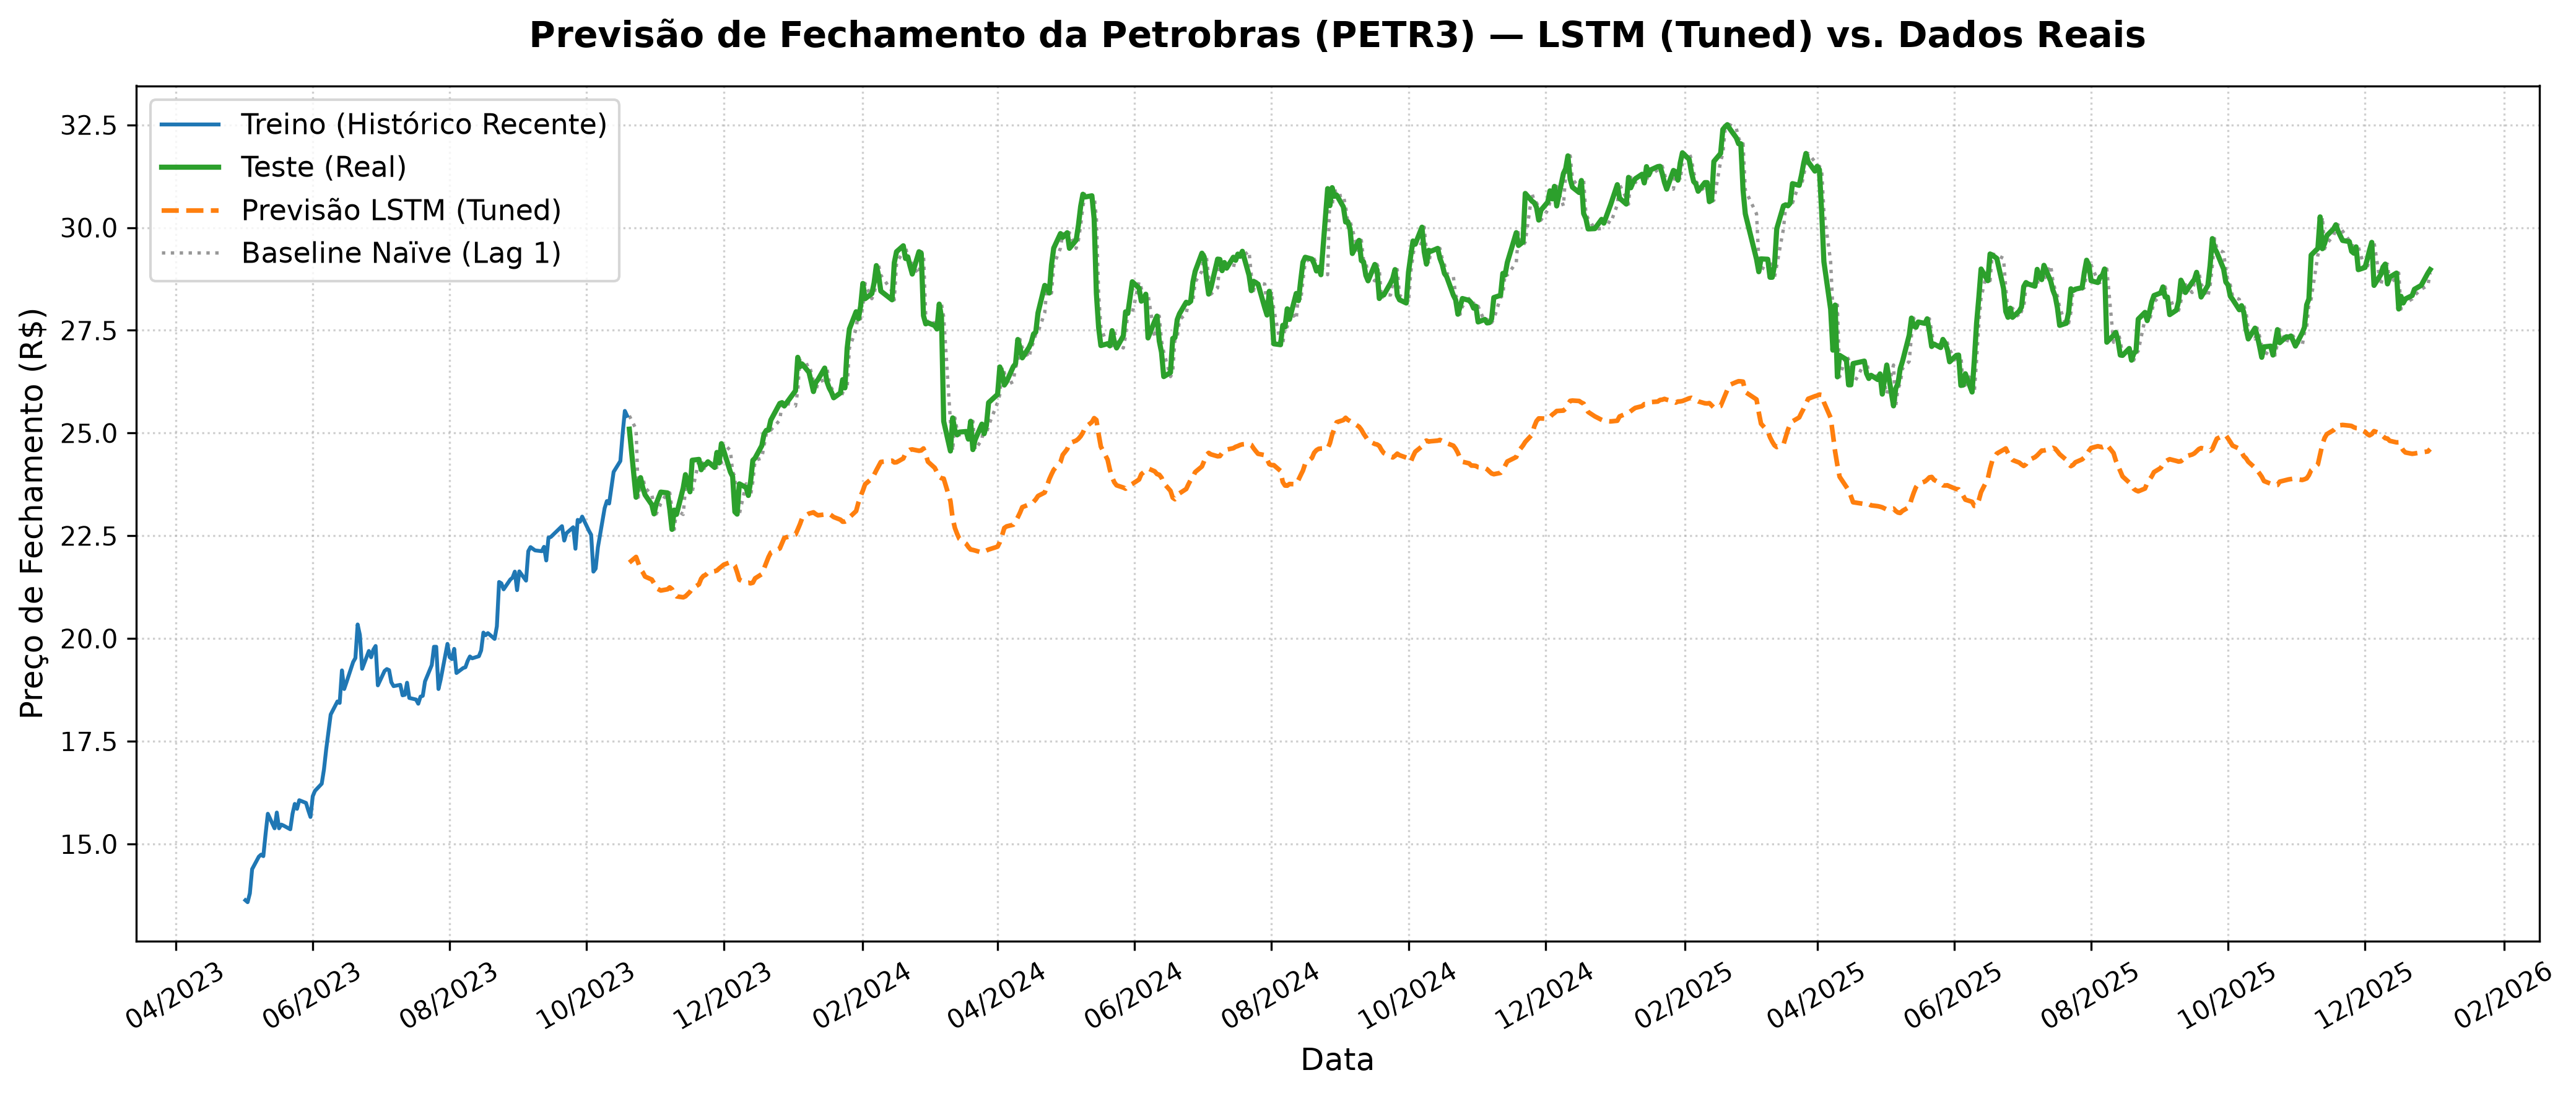

In [8]:
res_lstm = run_lstm(train_petro, test_petro, "petro", max_epochs=10)
plot_forecast(train_petro, test_petro, res_lstm["predictions"], "petro",
              model_name="LSTM (Tuned)", ticker_label="PETR3",
              company_name="Petrobras", baseline=res_lstm["ontem"])